#### Import Packages

In [22]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime

#### Import Dataset

In [23]:
df = pd.read_csv("/Users/ann/Documents/ddfg/elderly-housing-list-district-6-clean.csv", low_memory=False)

In [24]:
df

,neighborhood,zip,name_of_development,masshousing_number,site_address,site_address_telephone_number,management_company,management_company_telephone_number,PB_subsidy,MH_financed,FAM,ELD,bedroom_size_0_1,bedroom_size_2_3,bedroom_size_4_and_more,access_units
0,Jamaica Plain,2130,91 MINDEN STREET,94-038,91 MINDEN STREET,(617) 524-7788,"Peabody Properties, Inc.",(617) 524-7788,True,False,1,0,1,0,0,0
1,Jamaica Plain,2130,ANGELA WESTOVER HOUSE,00-105,49 PARLEY AVE,(617) 524-4520,"Peabody Properties, Inc.",(781) 794-1000,True,False,0,11,11,0,0,0
2,Jamaica Plain,2130,DOMICILIA III,00-160,40 GREEN ST,(617) 600-2447,"Domicilia - UCP, Inc.",(617) 600-2448,True,False,8,0,0,8,0,8
3,Jamaica Plain,2130,FARNSWORTH HOUSE,00-167,90 SOUTH ST,(617) 524-6971,"Rogerson Communities, Inc.",(617) 469-5830,True,True,1,75,69,7,0,8
4,Jamaica Plain,2130,FOREST HILLS,01-366,177 FOREST HILLS ST,(617) 524-8254,"Trinity Management, LLC",(617) 542-9185,True,False,87,0,28,59,0,0
5,Jamaica Plain,2130,FORESTVALE,01-367,14 ROCKVALE CIR,(617) 522-1829,"Reliant Realty Services, Inc.",(646) 734-6420,True,True,108,0,1,107,0,0
6,Jamaica Plain,2130,POND VIEW APARTMENTS,00-269,560 CENTRE ST,(617) 522-4520,"Peabody Properties, Inc.",(781) 794-1000,True,False,56,0,35,21,0,0
7,Jamaica Plain,2130,WOODBOURNE APARTMENTS,00-330,6 SOUTHBOURNE RD,(617) 232-2807,"The Community Builders, Inc.",(617) 857-8772,True,True,1,74,69,6,0,0
8,Roslindale,2131,CONWAY COURT,74-005,1 CONWAY STREET,(617) 574-1107,Beacon Residential Management,(617) 574-1100,False,True,28,0,14,14,0,0
9,Roslindale,2131,CUMMINS TOWERS,01-508,855 AMERICAN LEGION,(617) 327-4810,First Realty Management Co.,(617) 423-7000,True,False,239,0,123,116,0,2


In [25]:
df = pd.read_csv("elderly-housing-list-district-6-clean.csv", dtype={
    'neighborhood': 'string',
    'zip': 'int64', 
    'name_of_development': 'string',
    'masshousing_number': 'string',
    'site_address': 'string', 
    'site_address_telephone_number': 'string', 
    'management_company': 'string', 
    'management_company_telephone_number': 'string', 
    'PB_subsidy': 'bool', 
    'MH_financed': 'bool', 
    'FAM': 'int64', 
    'ELD': 'int64', 
    'bedroom_size_0_1': 'int64', 
    'bedroom_size_2_3': 'int64',
    'bedroom_size_4_and_more':'int64',
    'access_units': 'int64'    
})

print(df.dtypes)

neighborhood                           string[python]
zip                                             int64
name_of_development                    string[python]
masshousing_number                     string[python]
site_address                           string[python]
site_address_telephone_number          string[python]
management_company                     string[python]
management_company_telephone_number    string[python]
PB_subsidy                                       bool
MH_financed                                      bool
FAM                                             int64
ELD                                             int64
bedroom_size_0_1                                int64
bedroom_size_2_3                                int64
bedroom_size_4_and_more                         int64
access_units                                    int64
dtype: object


In [26]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18 entries, 0 to 17
Data columns (total 16 columns):
 #   Column                               Non-Null Count  Dtype 
---  ------                               --------------  ----- 
 0   neighborhood                         18 non-null     string
 1   zip                                  18 non-null     int64 
 2   name_of_development                  18 non-null     string
 3   masshousing_number                   18 non-null     string
 4   site_address                         18 non-null     string
 5   site_address_telephone_number        18 non-null     string
 6   management_company                   18 non-null     string
 7   management_company_telephone_number  18 non-null     string
 8   PB_subsidy                           18 non-null     bool  
 9   MH_financed                          18 non-null     bool  
 10  FAM                                  18 non-null     int64 
 11  ELD                                  18 non-nul

#### EDA

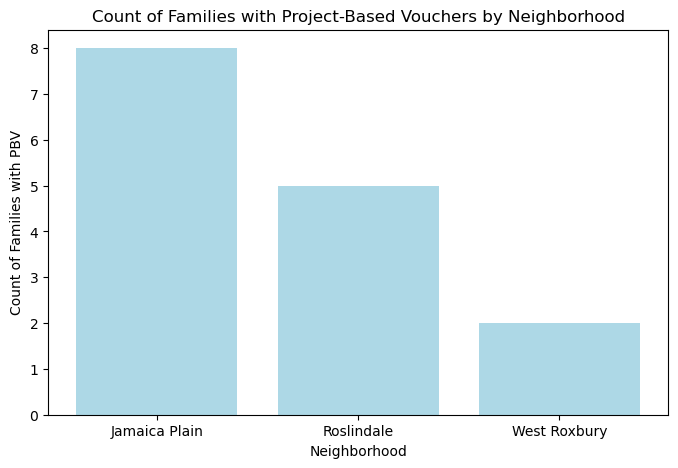

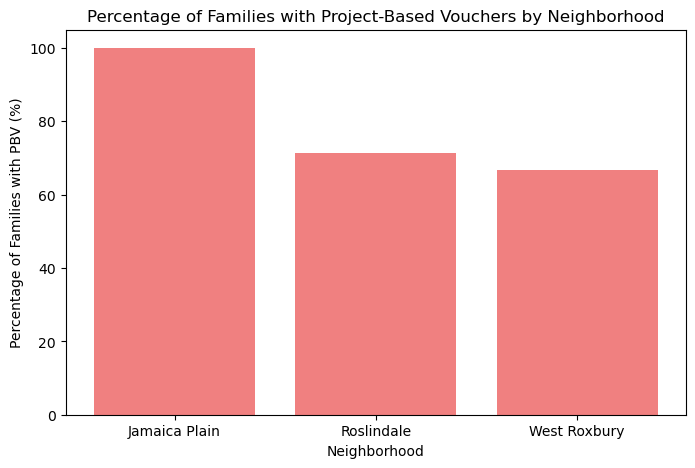

In [27]:
# Count of PBV families per neighborhood
pbv_counts = df.groupby('neighborhood')['PB_subsidy'].sum()
total_counts = df['neighborhood'].value_counts()
pbv_percentage = (pbv_counts / total_counts) * 100

# Plot 1: Count of Families with PBV
plt.figure(figsize=(8, 5))
plt.bar(pbv_counts.index, pbv_counts, color='lightblue')
plt.xlabel("Neighborhood")
plt.ylabel("Count of Families with PBV")
plt.title("Count of Families with Project-Based Vouchers by Neighborhood")
plt.xticks(rotation=0)
plt.show()

# Plot 2: Percentage of Families with PBV
plt.figure(figsize=(8, 5))
plt.bar(pbv_percentage.index, pbv_percentage, color='lightcoral')
plt.xlabel("Neighborhood")
plt.ylabel("Percentage of Families with PBV (%)")
plt.title("Percentage of Families with Project-Based Vouchers by Neighborhood")
plt.xticks(rotation=0)
plt.show()

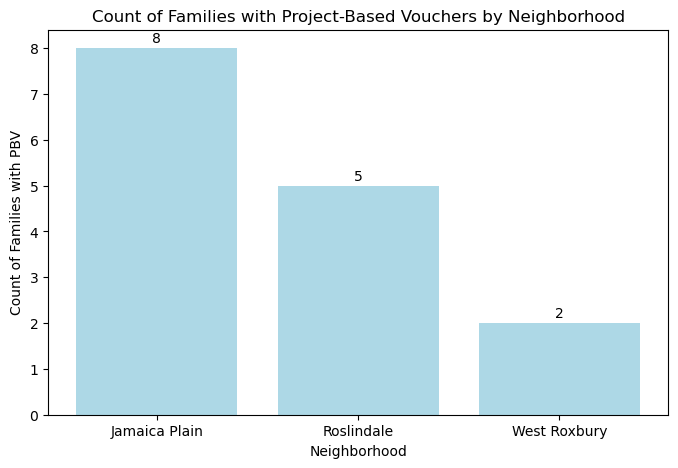

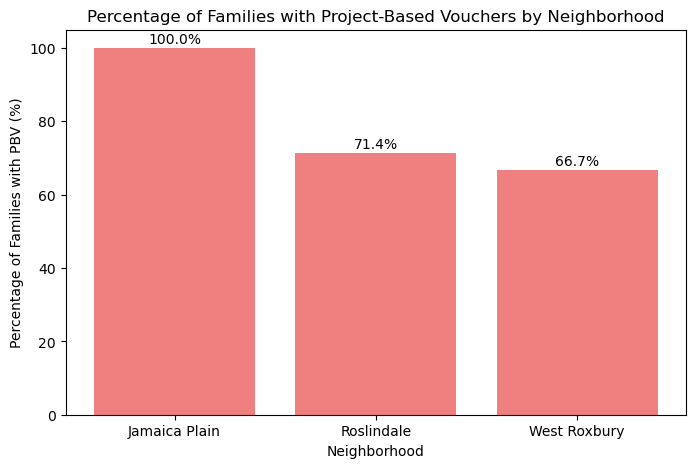

In [28]:
# Count of PBV families per neighborhood
pbv_counts = df.groupby('neighborhood')['PB_subsidy'].sum()
total_counts = df['neighborhood'].value_counts()
pbv_percentage = (pbv_counts / total_counts) * 100

# Plot 1: Count of Families with PBV
plt.figure(figsize=(8, 5))
bars = plt.bar(pbv_counts.index, pbv_counts, color='lightblue')

# Adding count on top of each bar
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width() / 2, yval + 0.05, int(yval), ha='center', va='bottom', fontsize=10)

plt.xlabel("Neighborhood")
plt.ylabel("Count of Families with PBV")
plt.title("Count of Families with Project-Based Vouchers by Neighborhood")
plt.xticks(rotation=0)
plt.show()

# Plot 2: Percentage of Families with PBV
plt.figure(figsize=(8, 5))
bars = plt.bar(pbv_percentage.index, pbv_percentage, color='lightcoral')

# Adding percentage on top of each bar
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width() / 2, yval + 0.5, f'{yval:.1f}%', ha='center', va='bottom', fontsize=10)

plt.xlabel("Neighborhood")
plt.ylabel("Percentage of Families with PBV (%)")
plt.title("Percentage of Families with Project-Based Vouchers by Neighborhood")
plt.xticks(rotation=0)
plt.show()

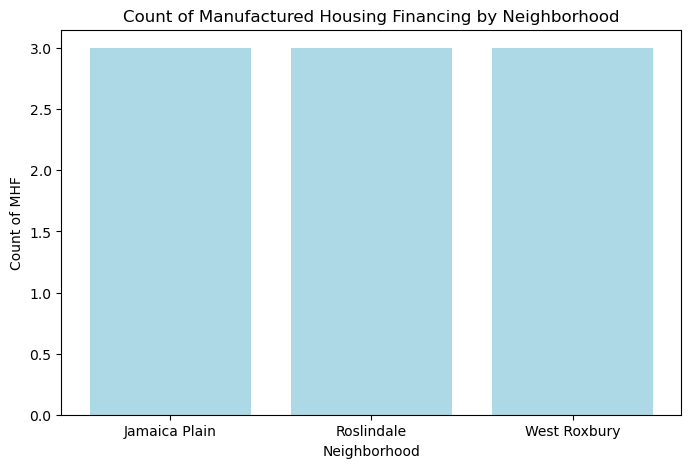

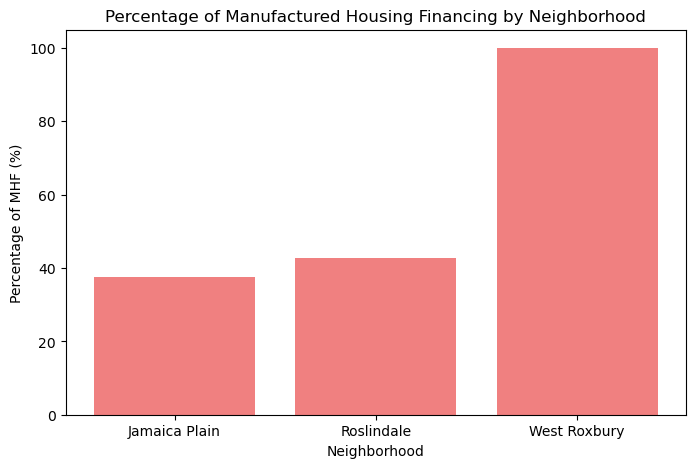

In [29]:
# Count of MH_financed per neighborhood
mh_counts = df.groupby('neighborhood')['MH_financed'].sum()
total_counts = df['neighborhood'].value_counts()
mh_percentage = (mh_counts / total_counts) * 100

# Plot 1: Count of Families with MH_financed
plt.figure(figsize=(8, 5))
plt.bar(mh_counts.index, mh_counts, color='lightblue')
plt.xlabel("Neighborhood")
plt.ylabel("Count of MHF")
plt.title("Count of Manufactured Housing Financing by Neighborhood")
plt.xticks(rotation=0)
plt.show()

# Plot 2: Percentage of Families with MH_financed
plt.figure(figsize=(8, 5))
plt.bar(mh_percentage.index, mh_percentage, color='lightcoral')
plt.xlabel("Neighborhood")
plt.ylabel("Percentage of MHF (%)")
plt.title("Percentage of Manufactured Housing Financing by Neighborhood")
plt.xticks(rotation=0)
plt.show()

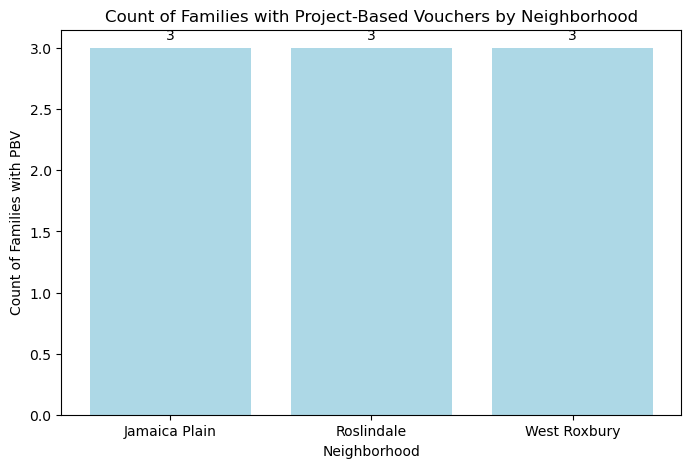

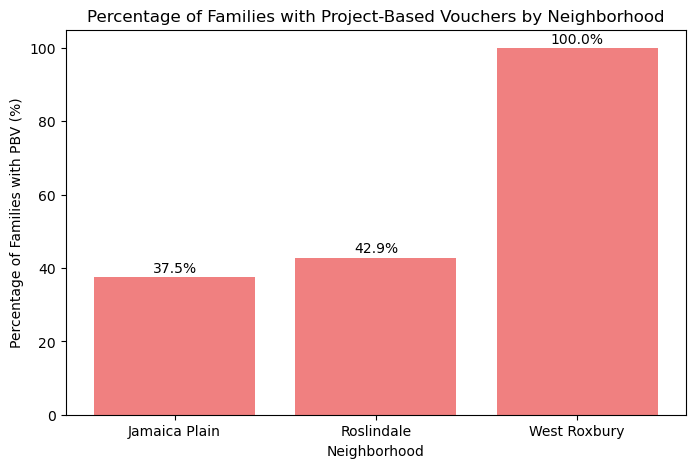

In [30]:
# Count of PBV families per neighborhood
mh_counts = df.groupby('neighborhood')['MH_financed'].sum()
total_counts = df['neighborhood'].value_counts()
mh_percentage = (mh_counts / total_counts) * 100

# Plot 1: Count of Families with PBV
plt.figure(figsize=(8, 5))
bars = plt.bar(mh_counts.index, mh_counts, color='lightblue')

# Adding count on top of each bar
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width() / 2, yval + 0.05, int(yval), ha='center', va='bottom', fontsize=10)

plt.xlabel("Neighborhood")
plt.ylabel("Count of Families with PBV")
plt.title("Count of Families with Project-Based Vouchers by Neighborhood")
plt.xticks(rotation=0)
plt.show()

# Plot 2: Percentage of Families with PBV
plt.figure(figsize=(8, 5))
bars = plt.bar(mh_percentage.index, mh_percentage, color='lightcoral')

# Adding percentage on top of each bar
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width() / 2, yval + 0.5, f'{yval:.1f}%', ha='center', va='bottom', fontsize=10)

plt.xlabel("Neighborhood")
plt.ylabel("Percentage of Families with PBV (%)")
plt.title("Percentage of Families with Project-Based Vouchers by Neighborhood")
plt.xticks(rotation=0)
plt.show()

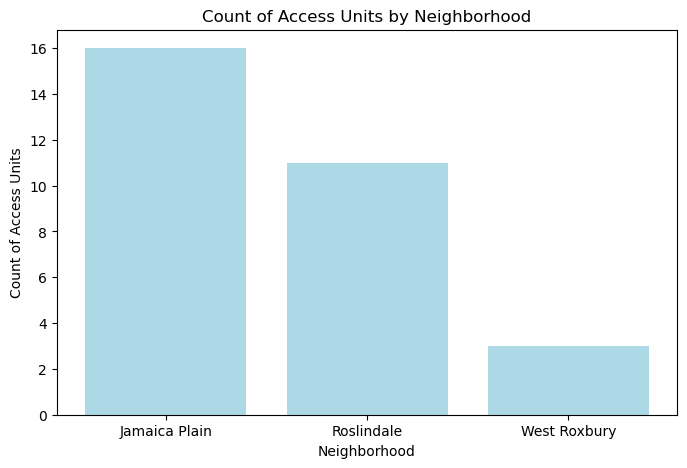

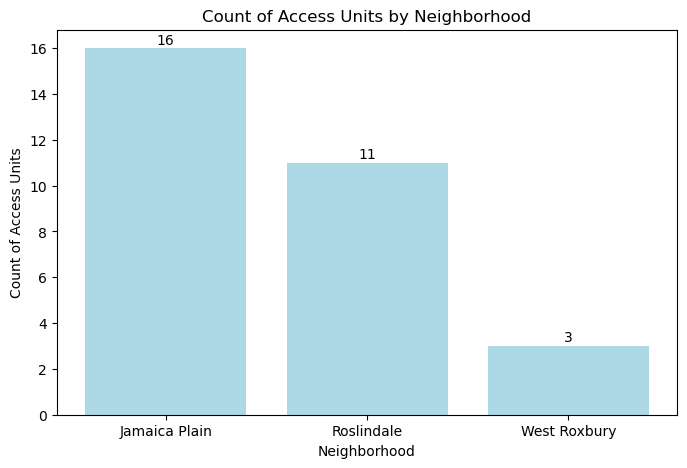

In [31]:
# Count of access units per neighborhood
access_counts = df.groupby('neighborhood')['access_units'].sum()
total_counts = df['neighborhood'].value_counts()

# Plot 1: Count of Access Units
plt.figure(figsize=(8, 5))
plt.bar(access_counts.index, access_counts, color='lightblue')
plt.xlabel("Neighborhood")
plt.ylabel("Count of Access Units")
plt.title("Count of Access Units by Neighborhood")
plt.xticks(rotation=0)
plt.show()

# Plot 2: Count of Access Units
plt.figure(figsize=(8, 5))
bars = plt.bar(access_counts.index, access_counts, color='lightblue')

# Adding count on top of each bar
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width() / 2, yval + 0.05, int(yval), ha='center', va='bottom', fontsize=10)

plt.xlabel("Neighborhood")
plt.ylabel("Count of Access Units")
plt.title("Count of Access Units by Neighborhood")
plt.xticks(rotation=0)
plt.show()

#### Elderly EDA

In [32]:
df_elderly = df[df['ELD'] != 0]

In [33]:
df_elderly

,neighborhood,zip,name_of_development,masshousing_number,site_address,site_address_telephone_number,management_company,management_company_telephone_number,PB_subsidy,MH_financed,FAM,ELD,bedroom_size_0_1,bedroom_size_2_3,bedroom_size_4_and_more,access_units
1,Jamaica Plain,2130,ANGELA WESTOVER HOUSE,00-105,49 PARLEY AVE,(617) 524-4520,"Peabody Properties, Inc.",(781) 794-1000,True,False,0,11,11,0,0,0
3,Jamaica Plain,2130,FARNSWORTH HOUSE,00-167,90 SOUTH ST,(617) 524-6971,"Rogerson Communities, Inc.",(617) 469-5830,True,True,1,75,69,7,0,8
7,Jamaica Plain,2130,WOODBOURNE APARTMENTS,00-330,6 SOUTHBOURNE RD,(617) 232-2807,"The Community Builders, Inc.",(617) 857-8772,True,True,1,74,69,6,0,0
11,Roslindale,2131,ROSLINDALE HOUSE,00-279,120 POPLAR ST,(617) 327-1503,"Rogerson Communities, Inc.",(617) 469-5830,True,True,1,83,83,1,0,4
15,West Roxbury,2132,CHERITON GROVE,00-135,20 CHERITON RD,(617) 323-6109,"The Community Builders, Inc.",(401) 946-4868,True,True,0,60,60,0,0,3
16,West Roxbury,2132,CHERITON HEIGHTS SENIO,10-012,20 Cheriton Road,(617) 323-6109,"The Community Builders, Inc.",(401) 946-4868,True,True,0,70,64,6,0,0


#### What housing options are available / deed restricted for elderly individuals?

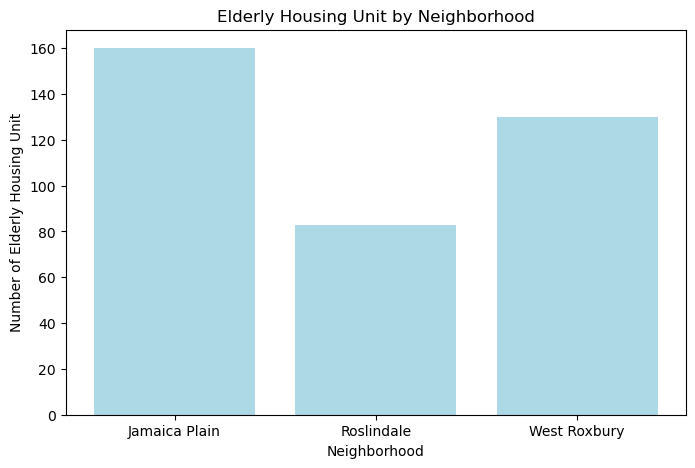

In [34]:
plt.figure(figsize=(8, 5))
df_elderly_sum = df_elderly.groupby('neighborhood')['ELD'].sum().reset_index()

plt.bar(df_elderly_sum['neighborhood'], df_elderly_sum['ELD'], color='lightblue')
plt.xlabel("Neighborhood")
plt.ylabel("Number of Elderly Housing Unit")
plt.title("Elderly Housing Unit by Neighborhood")
plt.xticks(rotation=0)
plt.show()

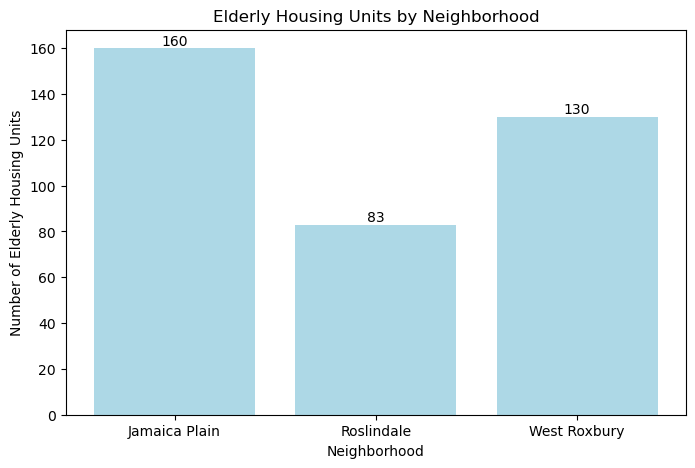

In [37]:
df_elderly_sum = df_elderly.groupby('neighborhood')['ELD'].sum().reset_index()

plt.figure(figsize=(8, 5))
bars = plt.bar(df_elderly_sum['neighborhood'], df_elderly_sum['ELD'], color='lightblue')

for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width() / 2, yval + 0.05, int(yval), ha='center', va='bottom', fontsize=10)
    
plt.xlabel("Neighborhood")
plt.ylabel("Number of Elderly Housing Units")
plt.title("Elderly Housing Units by Neighborhood")
plt.xticks(rotation=0)
plt.show()

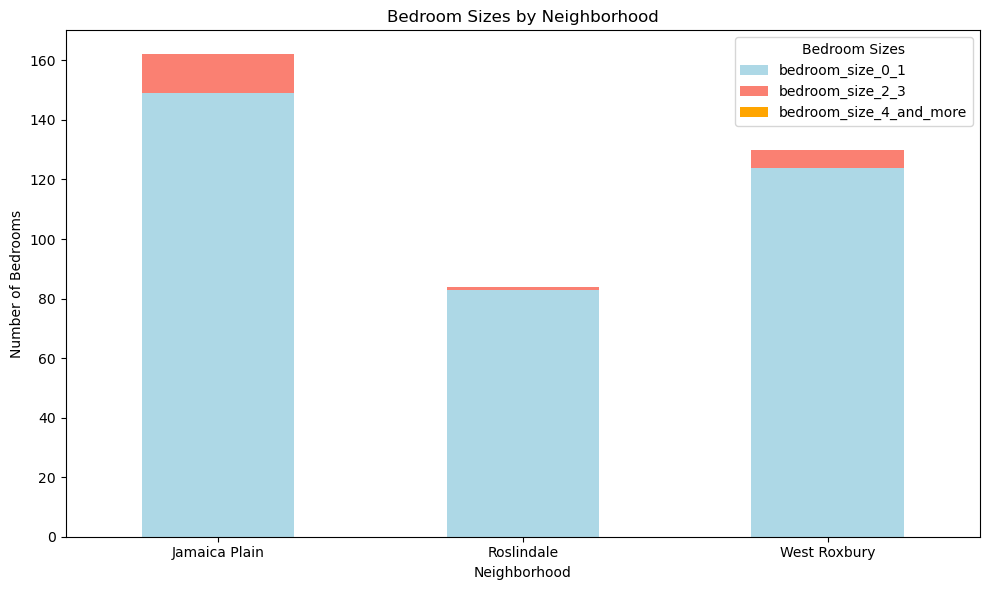

In [35]:
grouped_df_elderly = df_elderly.groupby('neighborhood')[['bedroom_size_0_1', 'bedroom_size_2_3', 'bedroom_size_4_and_more']].sum()
ax = grouped_df_elderly.plot(kind='bar', stacked=True, figsize=(10, 6), color = ['lightblue', 'salmon', 'orange'])

ax.set_xlabel('Neighborhood')
ax.set_ylabel('Number of Bedrooms')
ax.set_title('Bedroom Sizes by Neighborhood')
plt.legend(title='Bedroom Sizes')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()